# DataPact - Multi-Model System: Part 1, Model Size Selection and Benchmarking

**INFO 490, Team 15. Part 1, Steps 1.1-1.5: Hriday Agarwal.**
(Step 1.6 analysis and assembly: Tejas. Part 2 scaling simulations: Connor. Part 3 routing: Ashok; the version here was drafted during assembly.)

DataPact checks recurring data files against versioned *data contracts*. This notebook benchmarks
the **same 15 models from A6** on **25 realistic DataPact prompts** (5 prompt types x 5 prompts),
measuring **speed** (tokens per second, latency, time to first token) and **output quality**
(a 1-10 self-evaluation score from a fixed rubric).

**How to run:** in Google Colab choose *Runtime > Change runtime type > T4 GPU*, then
*Runtime > Run all*. It takes roughly 45-60 minutes. If the session crashes, *Run all* again:
finished models are skipped. Setting the environment variable `SMOKE_TEST=1` runs 2 models on
5 prompts for a quick check.

## Install libraries

* `transformers`: downloads a model by name and runs it.
* `accelerate`: places the model on the GPU.

PyTorch is already installed on Colab.

In [2]:
import subprocess
import sys

IN_COLAB = "google.colab" in sys.modules
packages = ["transformers==5.20.1", "accelerate==1.15.0", "pandas", "matplotlib"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *packages], check=True)
print("Running in Colab:", IN_COLAB)

Running in Colab: True


## Step 1.1: Model size categories

These are the 15 models from A6 (`llm-test/ai_prototype_light.ipynb`), all openly downloadable,
non-gated instruct/chat models. Parameter counts are the real totals from each model's
`safetensors` metadata. In A6 the free Colab session crashed on 7-8B models, so the team's A6
model set stays under 2B parameters, and the categories split that range into five groups of three:

| Model Category | Parameter Range | Models |
|---|---|---|
| Ultra-light | 0.1B - 0.4B | SmolLM2-135M, SmolLM-360M, SmolLM2-360M |
| Light | 0.4B - 0.6B | Qwen2-0.5B, Qwen2.5-0.5B, H2O-Danube3-500M |
| Small | 1.0B - 1.5B | TinyLlama-1.1B, Granite-3.1-1B-A400M, OLMo-2-1B |
| Medium | 1.5B - 1.7B | Qwen2.5-1.5B, StableLM-2-Zephyr-1.6B, Falcon3-1B |
| Large | 1.7B - 2.0B | SmolLM2-1.7B, H2O-Danube2-1.8B, Qwen1.5-1.8B |

"Large" means the largest of these models, not a 7B+ model.

In [3]:
import os

import pandas as pd

SMOKE_TEST = os.environ.get("SMOKE_TEST", "0") == "1"

MODELS = [
    # (category, Hugging Face id, parameters in billions)
    ("Ultra-light", "HuggingFaceTB/SmolLM2-135M-Instruct", 0.13),
    ("Ultra-light", "HuggingFaceTB/SmolLM-360M-Instruct", 0.36),
    ("Ultra-light", "HuggingFaceTB/SmolLM2-360M-Instruct", 0.36),
    ("Light", "Qwen/Qwen2-0.5B-Instruct", 0.49),
    ("Light", "Qwen/Qwen2.5-0.5B-Instruct", 0.49),
    ("Light", "h2oai/h2o-danube3-500m-chat", 0.51),
    ("Small", "TinyLlama/TinyLlama-1.1B-Chat-v1.0", 1.10),
    ("Small", "ibm-granite/granite-3.1-1b-a400m-instruct", 1.33),
    ("Small", "allenai/OLMo-2-0425-1B-Instruct", 1.48),
    ("Medium", "Qwen/Qwen2.5-1.5B-Instruct", 1.54),
    ("Medium", "stabilityai/stablelm-2-zephyr-1_6b", 1.64),
    ("Medium", "tiiuae/Falcon3-1B-Instruct", 1.67),
    ("Large", "HuggingFaceTB/SmolLM2-1.7B-Instruct", 1.71),
    ("Large", "h2oai/h2o-danube2-1.8b-chat", 1.83),
    ("Large", "Qwen/Qwen1.5-1.8B-Chat", 1.84),
]
CATEGORY_ORDER = ["Ultra-light", "Light", "Small", "Medium", "Large"]
if SMOKE_TEST:
    MODELS = [m for m in MODELS if m[1] in (
        "HuggingFaceTB/SmolLM2-135M-Instruct", "Qwen/Qwen2.5-0.5B-Instruct")]

import torch

if torch.cuda.is_available():
    DEVICE = "cuda"
elif torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

categories = pd.DataFrame(MODELS, columns=["Model Category", "Model", "Parameters (B)"])
print("Device:", DEVICE, "| smoke test:", SMOKE_TEST, "| models:", len(MODELS))
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
categories

Device: cuda | smoke test: False | models: 15
GPU: Tesla T4


,Model Category,Model,Parameters (B)
0,Ultra-light,HuggingFaceTB/SmolLM2-135M-Instruct,0.13
1,Ultra-light,HuggingFaceTB/SmolLM-360M-Instruct,0.36
2,Ultra-light,HuggingFaceTB/SmolLM2-360M-Instruct,0.36
3,Light,Qwen/Qwen2-0.5B-Instruct,0.49
4,Light,Qwen/Qwen2.5-0.5B-Instruct,0.49
5,Light,h2oai/h2o-danube3-500m-chat,0.51
6,Small,TinyLlama/TinyLlama-1.1B-Chat-v1.0,1.10
7,Small,ibm-granite/granite-3.1-1b-a400m-instruct,1.33
8,Small,allenai/OLMo-2-0425-1B-Instruct,1.48
9,Medium,Qwen/Qwen2.5-1.5B-Instruct,1.54


## Step 1.2: Prompt types

The five prompt types are the five things DataPact would ask a model to do:

| # | Prompt Type | What DataPact needs | Expected output |
|---|---|---|---|
| 1 | **Classification** | Decide whether a failed check means bad data or an out-of-date contract | JSON: `likely_cause` + `reason` |
| 2 | **Structured extraction** | Turn a data steward's plain-English rule request into contract fields | JSON: `dataset`, `column`, `rule_type`, `severity` |
| 3 | **Summarization** | Explain a whole validation run to a manager | At most 2 sentences, plain text |
| 4 | **Prediction** | Forecast the next run from the recent pass-rate history | JSON: `trend` + `next_run` |
| 5 | **Text generation** | Draft the email asking a data provider to fix a problem | 3-5 sentence email |

Three of the five return JSON because DataPact's code has to read those answers automatically.

## Step 1.3: The 25 evaluation prompts

Each prompt is a realistic input written in DataPact's own vocabulary (datasets, columns, rule
types such as `RANGE`, `ALLOWED_VALUES`, `UNIQUE`, `NOT_NULL`, `REGEX`, `TYPE_MATCH`).
**Every prompt has a known correct answer**, so outputs can be scored the same way for every model.

For the prediction prompts a run counts as passing when at least 98.0% of rows pass. The correct
trend and next result follow from the numbers by construction: steady rises or falls of about
0.3-0.7 points per run, or a flat series that varies by 0.2 points or less.

In [4]:
INSTRUCTIONS = {
    "Classification": (
        "You review failed data-quality checks for DataPact. A failure means either the incoming "
        "data is wrong (DATA_ISSUE) or the data is legitimate and the rule is out of date "
        "(CONTRACT_UPDATED).\n"
        "Reply with ONLY this JSON and no other text:\n"
        '{"likely_cause": "DATA_ISSUE" or "CONTRACT_UPDATED", "reason": "<one short sentence>"}'),
    "Structured extraction": (
        "Extract the data-contract rule described in this message from a data steward.\n"
        "rule_type must be one of: RANGE, ALLOWED_VALUES, REGEX, UNIQUE, NOT_NULL, TYPE_MATCH.\n"
        "severity must be ERROR (blocks the upload) or WARNING (only flags it).\n"
        "Reply with ONLY this JSON and no other text:\n"
        '{"dataset": "...", "column": "...", "rule_type": "...", "severity": "..."}'),
    "Summarization": (
        "Summarize this validation run for a manager in at most 2 sentences (60 words maximum). "
        "Mention the overall result, how many rules failed, and the failure that affected the "
        "most rows. Plain text only, no lists or JSON."),
    "Prediction": (
        "These are the row pass rates of the last six validation runs, oldest first. A run passes "
        "when at least 98.0% of rows pass. Predict the trend and whether the next run will pass if "
        "the trend continues.\n"
        "Reply with ONLY this JSON and no other text:\n"
        '{"trend": "IMPROVING" or "DECLINING" or "STABLE", "next_run": "PASS" or "FAIL"}'),
    "Text generation": (
        "Write a short email (3 to 5 sentences) to the data provider asking them to fix the problem "
        "below. Start with \"Hello\", mention the dataset, the column and the number of failed "
        "rows, say what they should do, and sign off as \"DataPact\"."),
}

ACTION = r"\b(correct|fix|update|resend|re-send|re-export|reexport|re-upload|review|investigate|check|remove|fill|replace)\w*"

PROMPTS = [
    # ---------------- Classification ----------------
    dict(id="C1", type="Classification", truth={"likely_cause": "DATA_ISSUE"}, input=(
        "Dataset: Weekly Sales Extract\nColumn: unit_price\nRule: RANGE {\"min\": 0.01, \"max\": 5000}\n"
        "Rows failed: 23 of 13,120\nSample values: [-15.00, 0.00, -4.99]")),
    dict(id="C2", type="Classification", truth={"likely_cause": "CONTRACT_UPDATED"}, input=(
        "Dataset: Monthly Enrollment Export\nColumn: residency\n"
        "Rule: ALLOWED_VALUES [\"IN_STATE\", \"OUT_OF_STATE\", \"INTERNATIONAL\"]\n"
        "Rows failed: 380 of 4,812\nSample values: [\"ONLINE_ONLY\", \"ONLINE_ONLY\", \"ONLINE_ONLY\"]")),
    dict(id="C3", type="Classification", truth={"likely_cause": "DATA_ISSUE"}, input=(
        "Dataset: Sensor Readings - Lab 3\nColumn: timestamp\nRule: NOT_NULL\n"
        "Rows failed: 31 of 8,640\nSample values: [null, null, null]")),
    dict(id="C4", type="Classification", truth={"likely_cause": "CONTRACT_UPDATED"}, input=(
        "Dataset: Facilities Work Orders\nColumn: building_code\n"
        "Rule: ALLOWED_VALUES [\"SIEBEL\", \"ARC\", \"UNION\"]\n"
        "Rows failed: 260 of 2,210\nSample values: [\"CIF\", \"CIF\", \"CIF\"]")),
    dict(id="C5", type="Classification", truth={"likely_cause": "DATA_ISSUE"}, input=(
        "Dataset: Payroll Deductions Export\nColumn: amount\nRule: TYPE_MATCH {\"type\": \"number\"}\n"
        "Rows failed: 3 of 3,402\nSample values: [\"12..50\", \"N/A\", \"$\"]")),
    # ---------------- Structured extraction ----------------
    dict(id="E1", type="Structured extraction", input=(
        "Hi, for the Library Circulation Log, every checkout_id must appear only once. Treat any "
        "duplicates as an error that blocks the upload. Thanks, Maria"),
        truth={"dataset": "Library Circulation Log", "column": "checkout_id",
               "rule_type": "UNIQUE", "severity": "ERROR"}),
    dict(id="E2", type="Structured extraction", input=(
        "Quick request: in the Sensor Readings - Lab 3 file, humidity_pct should always be between "
        "0 and 100. If it isn't, just flag a warning, don't block the load."),
        truth={"dataset": "Sensor Readings - Lab 3", "column": "humidity_pct",
               "rule_type": "RANGE", "severity": "WARNING"}),
    dict(id="E3", type="Structured extraction", input=(
        "Starting next month the Monthly Enrollment Export must never have an empty advisor_email. "
        "Missing values should fail the run."),
        truth={"dataset": "Monthly Enrollment Export", "column": "advisor_email",
               "rule_type": "NOT_NULL", "severity": "ERROR"}),
    dict(id="E4", type="Structured extraction", input=(
        "For the Course Catalog Snapshot, course_code has to look like four capital letters followed "
        "by three digits, for example INFO490. Mismatches should only be flagged as warnings."),
        truth={"dataset": "Course Catalog Snapshot", "column": "course_code",
               "rule_type": "REGEX", "severity": "WARNING"}),
    dict(id="E5", type="Structured extraction", input=(
        "Payroll Deductions Export: pay_frequency may only be WEEKLY, BIWEEKLY or MONTHLY. Anything "
        "else is an error and must block the upload."),
        truth={"dataset": "Payroll Deductions Export", "column": "pay_frequency",
               "rule_type": "ALLOWED_VALUES", "severity": "ERROR"}),
    # ---------------- Summarization ----------------
    dict(id="S1", type="Summarization", input=(
        "Validation run #412 - Monthly Enrollment Export (4,812 rows)\nRules checked: 6. Passed: 5. Failed: 1.\n"
        "- FAILED credit_hours RANGE {min 0, max 24}: 47 rows (samples 31, 99, -2)\nOverall result: FAILED"),
        truth={"facts": [r"enrol", r"fail", r"\b(1|one|single)\b", r"credit[_ ]hours"]}),
    dict(id="S2", type="Summarization", input=(
        "Validation run #88 - Sensor Readings - Lab 3 (8,640 rows)\nRules checked: 8. Passed: 6. Failed: 2.\n"
        "- FAILED temperature_c RANGE {min -10, max 50}: 6 rows (samples -9999)\n"
        "- FAILED timestamp NOT_NULL: 31 rows\nOverall result: FAILED"),
        truth={"facts": [r"sensor", r"fail", r"\b(2|two)\b", r"timestamp"]}),
    dict(id="S3", type="Summarization", input=(
        "Validation run #231 - Library Circulation Log (9,800 rows)\nRules checked: 7. Passed: 7. Failed: 0.\n"
        "No failures.\nOverall result: PASSED"),
        truth={"facts": [r"library", r"pass", r"\b(7|seven|all|0|no|zero|none)\b"]}),
    dict(id="S4", type="Summarization", input=(
        "Validation run #57 - Payroll Deductions Export (3,402 rows)\nRules checked: 5. Passed: 4. Failed: 1.\n"
        "- FAILED deduction_code ALLOWED_VALUES [FED, STATE, MEDICARE, SOCSEC]: 512 rows (value HSA)\n"
        "Overall result: FAILED"),
        truth={"facts": [r"payroll", r"fail", r"\b(1|one|single)\b", r"deduction[_ ]code|\bhsa\b"]}),
    dict(id="S5", type="Summarization", input=(
        "Validation run #19 - Facilities Work Orders (2,210 rows)\nRules checked: 6. Passed: 4. Failed: 2.\n"
        "- FAILED order_id UNIQUE: 14 rows\n"
        "- FAILED priority ALLOWED_VALUES [LOW, MEDIUM, HIGH]: 140 rows (value URGENT)\nOverall result: FAILED"),
        truth={"facts": [r"facilit|work order", r"fail", r"\b(2|two)\b", r"priority|urgent"]}),
    # ---------------- Prediction ----------------
    dict(id="P1", type="Prediction", truth={"trend": "DECLINING", "next_run": "FAIL"},
         input="Dataset: Monthly Enrollment Export\nPass rates: 99.6%, 99.4%, 99.1%, 98.7%, 98.4%, 98.1%"),
    dict(id="P2", type="Prediction", truth={"trend": "IMPROVING", "next_run": "PASS"},
         input="Dataset: Sensor Readings - Lab 3\nPass rates: 95.2%, 96.0%, 96.9%, 97.5%, 98.2%, 98.9%"),
    dict(id="P3", type="Prediction", truth={"trend": "STABLE", "next_run": "PASS"},
         input="Dataset: Library Circulation Log\nPass rates: 99.5%, 99.6%, 99.5%, 99.4%, 99.5%, 99.5%"),
    dict(id="P4", type="Prediction", truth={"trend": "STABLE", "next_run": "FAIL"},
         input="Dataset: Payroll Deductions Export\nPass rates: 97.0%, 96.9%, 97.1%, 97.0%, 96.9%, 97.0%"),
    dict(id="P5", type="Prediction", truth={"trend": "DECLINING", "next_run": "FAIL"},
         input="Dataset: Facilities Work Orders\nPass rates: 99.9%, 99.5%, 99.2%, 98.9%, 98.5%, 98.2%"),
    # ---------------- Text generation ----------------
    dict(id="G1", type="Text generation", input=(
        "Dataset: Weekly Sales Extract\nColumn: unit_price\nProblem: 23 rows have a zero or negative price."),
        truth={"facts": [r"sales", r"unit[_ ]price", r"\b23\b", ACTION]}),
    dict(id="G2", type="Text generation", input=(
        "Dataset: Sensor Readings - Lab 3\nColumn: timestamp\nProblem: 31 rows are missing their timestamp."),
        truth={"facts": [r"sensor", r"timestamp", r"\b31\b", ACTION]}),
    dict(id="G3", type="Text generation", input=(
        "Dataset: Monthly Enrollment Export\nColumn: student_id\nProblem: 12 rows have student IDs that "
        "are not exactly 8 digits."),
        truth={"facts": [r"enrol", r"student[_ ]id", r"\b12\b", ACTION]}),
    dict(id="G4", type="Text generation", input=(
        "Dataset: Facilities Work Orders\nColumn: order_id\nProblem: 14 rows repeat an order_id that "
        "already appears in the file."),
        truth={"facts": [r"facilit|work order", r"order[_ ]id", r"\b14\b", ACTION]}),
    dict(id="G5", type="Text generation", input=(
        "Dataset: Course Catalog Snapshot\nColumn: credit_hours\nProblem: 18 rows list a course worth 0 "
        "credit hours, but every course must be worth at least 1."),
        truth={"facts": [r"catalog|course", r"credit[_ ]hours", r"\b18\b", ACTION]}),
]
PROMPT_TYPES = list(INSTRUCTIONS)
MAX_NEW_TOKENS = {"Classification": 120, "Structured extraction": 120, "Summarization": 140,
                  "Prediction": 80, "Text generation": 220}

if SMOKE_TEST:
    PROMPTS = [p for p in PROMPTS if p["id"].endswith("1")]

assert len({p["id"] for p in PROMPTS}) == len(PROMPTS)
prompt_table = pd.DataFrame([{"Prompt Type": p["type"], "ID": p["id"], "Input": p["input"]}
                             for p in PROMPTS])
print(len(PROMPTS), "prompts:", prompt_table["Prompt Type"].value_counts().to_dict())
pd.set_option("display.max_colwidth", 120)
prompt_table

25 prompts: {'Classification': 5, 'Structured extraction': 5, 'Summarization': 5, 'Prediction': 5, 'Text generation': 5}


,Prompt Type,ID,Input
0,Classification,C1,"Dataset: Weekly Sales Extract\nColumn: unit_price\nRule: RANGE {""min"": 0.01, ""max"": 5000}\nRows failed: 23 of 13,120..."
1,Classification,C2,"Dataset: Monthly Enrollment Export\nColumn: residency\nRule: ALLOWED_VALUES [""IN_STATE"", ""OUT_OF_STATE"", ""INTERNATIO..."
2,Classification,C3,"Dataset: Sensor Readings - Lab 3\nColumn: timestamp\nRule: NOT_NULL\nRows failed: 31 of 8,640\nSample values: [null,..."
3,Classification,C4,"Dataset: Facilities Work Orders\nColumn: building_code\nRule: ALLOWED_VALUES [""SIEBEL"", ""ARC"", ""UNION""]\nRows failed..."
4,Classification,C5,"Dataset: Payroll Deductions Export\nColumn: amount\nRule: TYPE_MATCH {""type"": ""number""}\nRows failed: 3 of 3,402\nSa..."
5,Structured extraction,E1,"Hi, for the Library Circulation Log, every checkout_id must appear only once. Treat any duplicates as an error that ..."
6,Structured extraction,E2,"Quick request: in the Sensor Readings - Lab 3 file, humidity_pct should always be between 0 and 100. If it isn't, ju..."
7,Structured extraction,E3,Starting next month the Monthly Enrollment Export must never have an empty advisor_email. Missing values should fail...
8,Structured extraction,E4,"For the Course Catalog Snapshot, course_code has to look like four capital letters followed by three digits, for exa..."
9,Structured extraction,E5,"Payroll Deductions Export: pay_frequency may only be WEEKLY, BIWEEKLY or MONTHLY. Anything else is an error and must..."


## Step 1.4: Evaluation metrics

Every output gets a **self-evaluation score from 1 to 10**, built from four criteria:

| Metric | Points | Description |
|---|---|---|
| **Instruction adherence** | 3 | Did the model follow the instructions: allowed values only, exactly the requested keys, no extra text around JSON, the sentence and word limits? |
| **Accuracy** | 4 | Was the answer correct? Classification and prediction: the right label. Extraction: the share of the 4 fields that match. Summaries and emails: the share of the required facts mentioned (dataset, result or column, the key number, the main issue or the requested action). Values are compared ignoring case, spaces and underscores. An answer that mostly copies the input (over half of its 5-word sequences appear in the prompt) earns no accuracy points, because repeating the report is not summarizing it. |
| **Clarity** | 2 | Is it understandable? It does not loop or repeat itself, and it is not cut off mid-answer. For classification, the reason must be a real sentence (3+ words), not just a label. |
| **Structure** | 1 | Is it in the expected format? Valid JSON for the JSON types, plain prose for summaries, and an email that opens with "Hello" and signs off as DataPact. |

The score is `max(1, adherence + accuracy + clarity + structure)`, rounded to one decimal.

Limits used for adherence: summaries need 1-2 sentences and at most 60 words; emails need 3-7
sentences (the requested 3-5, plus the "Hello" and sign-off lines, which count as sentences when
they sit on their own line) and at most 130 words.

**Why a fixed rubric, applied by code?** 15 models x 25 prompts gives 375 answers. Scoring them
with the same written rules makes every score repeatable and comparable between models; scoring
by eye would drift. The rules were written and tested on hand-written good and bad answers
(next cell) before the benchmark. A 2-model trial run then exposed three loopholes (a label used
as the "reason", extra JSON keys, and a summary that copied the input), which were closed before
the full run; the trial's examples are among the self-tests. Sample outputs are printed at the end so the scores
can be checked by reading them.

In [5]:
import json
import re

ALLOWED = {
    "Classification": {"likely_cause": {"DATA_ISSUE", "CONTRACT_UPDATED"}},
    "Structured extraction": {"rule_type": {"RANGE", "ALLOWED_VALUES", "REGEX", "UNIQUE",
                                            "NOT_NULL", "TYPE_MATCH"},
                              "severity": {"ERROR", "WARNING"}},
    "Prediction": {"trend": {"IMPROVING", "DECLINING", "STABLE"}, "next_run": {"PASS", "FAIL"}},
}
KEYS = {"Classification": {"likely_cause", "reason"},
        "Structured extraction": {"dataset", "column", "rule_type", "severity"},
        "Prediction": {"trend", "next_run"}}


def is_looping(text):
    # True when many 4-word sequences repeat: the model is stuck in a loop.
    words = re.findall(r"\w+", text.lower())
    grams = [tuple(words[i:i + 4]) for i in range(len(words) - 3)]
    return len(grams) >= 8 and 1 - len(set(grams)) / len(grams) > 0.3


def sentences(text):
    return [s for s in re.split(r"(?<=[.!?])\s+", text.strip()) if re.search(r"\w", s)]


def parse_json(text):
    # Returns (dict or None, only_json): only_json is False when there is other text around it.
    stripped = re.sub(r"^```(?:json)?\s*|\s*```$", "", text.strip())
    match = re.search(r"\{.*\}", stripped, re.DOTALL)
    if not match:
        return None, False
    try:
        data = json.loads(match.group(0))
    except json.JSONDecodeError:
        return None, False
    if not isinstance(data, dict):
        return None, False
    return data, stripped == match.group(0)


def norm(value):
    # "Library_Circulation_Log" and "Library Circulation Log" count as the same value.
    return re.sub(r"[^A-Z0-9]", "", str(value).upper())


def clarity_points(text, truncated):
    return (0 if is_looping(text) else 1) + (0 if truncated else 1)


def score_json(prompt, text, truncated):
    kind, truth = prompt["type"], prompt["truth"]
    data, only_json = parse_json(text)
    s = {"adherence": 0.0, "accuracy": 0.0, "clarity": clarity_points(text, truncated),
         "structure": 1.0 if data is not None else 0.0}
    if data is None:
        return s
    allowed_ok = all(norm(data.get(k, "")) in {norm(a) for a in v} for k, v in ALLOWED[kind].items())
    s["adherence"] = (1.0 if set(data) == KEYS[kind] else 0.0) + (1.0 if allowed_ok else 0.0) \
        + (1.0 if only_json else 0.0)
    if kind == "Classification" and len(re.findall(r"[A-Za-z]+", str(data.get("reason", "")))) < 3:
        s["clarity"] = max(0, s["clarity"] - 1)  # the reason must be a real sentence
    matches = [norm(data.get(k, "")) == norm(v) for k, v in truth.items()]
    s["accuracy"] = 4.0 * sum(matches) / len(matches)
    return s


def copy_ratio(text, source):
    # Share of the answer's 5-word sequences that appear word for word in the input.
    def grams(t):
        w = re.findall(r"\w+", t.lower())
        return {tuple(w[i:i + 5]) for i in range(len(w) - 4)}
    answer = grams(text)
    return len(answer & grams(source)) / len(answer) if answer else 0.0


def facts_found(text, facts):
    return sum(bool(re.search(f, text, re.IGNORECASE)) for f in facts) / len(facts)


def score_summary(prompt, text, truncated):
    n_sent, n_words = len(sentences(text)), len(re.findall(r"\w+", text))
    prose = not re.search(r"^\s*([-*•]|\d+[.)])\s", text, re.MULTILINE) and "{" not in text
    return {"adherence": (1.5 if 1 <= n_sent <= 2 else 0.0) + (1.5 if 0 < n_words <= 60 else 0.0),
            "accuracy": 0.0 if copy_ratio(text, prompt["input"]) > 0.5
            else 4.0 * facts_found(text, prompt["truth"]["facts"]),
            "clarity": clarity_points(text, truncated),
            "structure": 1.0 if prose and text.strip() else 0.0}


def score_email(prompt, text, truncated):
    body = text.strip()
    n_sent, n_words = len(sentences(body)), len(re.findall(r"\w+", body))
    starts_hello = bool(re.match(r"^\W*hello\b", body, re.IGNORECASE))
    signs_off = "datapact" in body[-80:].lower()
    return {"adherence": (1.5 if 3 <= n_sent <= 7 else 0.0) + (1.5 if 0 < n_words <= 130 else 0.0),
            "accuracy": 0.0 if copy_ratio(body, prompt["input"]) > 0.5
            else 4.0 * facts_found(body, prompt["truth"]["facts"]),
            "clarity": clarity_points(body, truncated),
            "structure": 0.5 * starts_hello + 0.5 * signs_off}


def evaluate(prompt, text, truncated=False):
    kind = prompt["type"]
    if kind in KEYS:
        s = score_json(prompt, text, truncated)
    elif kind == "Summarization":
        s = score_summary(prompt, text, truncated)
    else:
        s = score_email(prompt, text, truncated)
    s["score"] = round(max(1.0, sum(s.values())), 1)
    return s


# --- Test the rubric on hand-written answers before running any model ---
P = {p["id"]: p for p in PROMPTS}
if not SMOKE_TEST:
    checks = [
        ("C1", '{"likely_cause": "DATA_ISSUE", "reason": "Prices cannot be negative."}', 10),
        ("C1", '{"likely_cause": "CONTRACT_UPDATED", "reason": "This looks like a new pricing policy."}', 6),
        ("C1", 'Sure! ```json\n{"likely_cause": "DATA_ISSUE", "reason": "The prices are invalid."}\n```', 9),
        ("C1", "The data is wrong. The data is wrong. The data is wrong. The data is wrong. "
               "The data is wrong. The data is wrong.", 1),
        ("E1", '{"dataset": "Library Circulation Log", "column": "checkout_id", '
               '"rule_type": "UNIQUE", "severity": "ERROR"}', 10),
        ("E1", '{"dataset": "Library Circulation Log", "column": "checkout_id", '
               '"rule_type": "DUPLICATE", "severity": "ERROR"}', 8),
        ("E1", '{"dataset": "Library_Circulation_Log", "column": "checkout_id", '
               '"rule_type": "unique", "severity": "ERROR"}', 10),
        ("C1", '{"likely_cause": "DATA_ISSUE", "reason": "CONTRACT_UPDATED", "sample_values": [1]}', 8),
        ("S1", P["S1"]["input"], 3.5),
        ("S1", "Run #412 of the Monthly Enrollment Export failed because 1 rule broke: "
               "47 rows had credit_hours outside 0-24.", 10),
        ("P1", '{"trend": "DECLINING", "next_run": "FAIL"}', 10),
        ("P1", '{"trend": "IMPROVING", "next_run": "FAIL"}', 8),
        ("G1", "Hello, our check of the Weekly Sales Extract found 23 rows where unit_price is zero "
               "or negative. Please correct these prices and resend the file. Thank you for your "
               "help. Best regards, DataPact", 10),
    ]
    for pid, answer, expected in checks:
        got = evaluate(P[pid], answer)["score"]
        assert got == expected, (pid, answer[:40], got, expected)
    print(f"Rubric self-test passed on {len(checks)} hand-written answers.")

Rubric self-test passed on 13 hand-written answers.


## Downloading, loading and running a model

Same approach as A6: each model is downloaded right before its test, models whose files are
over 1 GB are deleted straight after, stalled downloads are retried, and each model is loaded
in 16-bit floats straight onto the GPU. **Greedy decoding** (`do_sample=False`) makes every
answer repeatable.

**Speed measurements** (the model is warmed up with one short generation first, so loading
costs are not counted):

* **Latency**: seconds from sending the prompt to receiving the complete answer.
* **Time to first token (TTFT)**: seconds until the first new token, measured by generating
  exactly one token. This is what a user waits for before anything appears.
* **Tokens/sec**: new tokens divided by latency.
* **Peak GPU memory**: the most GPU memory the model used (CUDA only).

In [6]:
import gc
import shutil
import time

os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "60")
from huggingface_hub import scan_cache_dir, snapshot_download
from transformers import AutoModelForCausalLM, AutoTokenizer

WEIGHT_FILES = ["*.json", "*.safetensors", "*.model", "*.txt", "*.py", "*.tiktoken"]
DELETE_ABOVE_GB = 1.0


def download(model_id, attempts=3):
    for attempt in range(1, attempts + 1):
        try:
            return snapshot_download(model_id, allow_patterns=WEIGHT_FILES)
        except Exception as error:
            print(f"   download attempt {attempt} failed: {type(error).__name__}")
            if attempt == attempts:
                raise
            time.sleep(10)


def tidy_up(model_id):
    for repo in scan_cache_dir().repos:
        if repo.repo_id == model_id and repo.size_on_disk / 1e9 > DELETE_ABOVE_GB:
            scan_cache_dir().delete_revisions(*[r.commit_hash for r in repo.revisions]).execute()
            print(f"   deleted its {repo.size_on_disk / 1e9:.1f} GB of files")


def load(model_id):
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    kwargs = {"dtype": torch.float16 if DEVICE != "cpu" else torch.float32}
    if DEVICE == "cuda":
        kwargs["device_map"] = "cuda"
    model = AutoModelForCausalLM.from_pretrained(model_id, **kwargs)
    if DEVICE != "cuda":
        model.to(DEVICE)
    model.eval()
    return tokenizer, model


def unload(model):
    del model
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE == "mps":
        torch.mps.empty_cache()


def sync():
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    elif DEVICE == "mps":
        torch.mps.synchronize()


def build_messages(prompt):
    return [{"role": "user", "content": INSTRUCTIONS[prompt["type"]] + "\n\n" + prompt["input"]}]


def timed_generate(tokenizer, model, inputs, max_new_tokens):
    sync()
    start = time.perf_counter()
    with torch.no_grad():
        output = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                                pad_token_id=tokenizer.pad_token_id)
    sync()
    return output, time.perf_counter() - start


def run_model(model_id, category, params):
    tokenizer, model = load(model_id)
    # Warm-up so the first prompt does not pay one-off start-up costs.
    warm = tokenizer.apply_chat_template([{"role": "user", "content": "Hello"}],
                                         add_generation_prompt=True, return_tensors="pt",
                                         return_dict=True).to(model.device)
    timed_generate(tokenizer, model, warm, 4)
    if DEVICE == "cuda":
        torch.cuda.reset_peak_memory_stats()
    rows = []
    for prompt in PROMPTS:
        inputs = tokenizer.apply_chat_template(build_messages(prompt), add_generation_prompt=True,
                                               return_tensors="pt", return_dict=True).to(model.device)
        n_prompt = inputs["input_ids"].shape[1]
        limit = MAX_NEW_TOKENS[prompt["type"]]
        _, ttft = timed_generate(tokenizer, model, inputs, 1)
        output, seconds = timed_generate(tokenizer, model, inputs, limit)
        new_tokens = output[0][n_prompt:]
        text = tokenizer.decode(new_tokens, skip_special_tokens=True).strip()
        truncated = len(new_tokens) >= limit
        rows.append({
            "Model": model_id.split("/")[-1], "model_id": model_id, "Model Category": category,
            "Parameters (B)": params, "Prompt Type": prompt["type"], "Prompt ID": prompt["id"],
            "Prompt": prompt["input"], "prompt_tokens": n_prompt, "new_tokens": len(new_tokens),
            "Latency (s)": round(seconds, 3), "TTFT (s)": round(ttft, 3),
            "Tokens/sec": round(len(new_tokens) / seconds, 1) if seconds else None,
            "truncated": truncated, "output": text, **evaluate(prompt, text, truncated),
        })
    peak = torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else None
    for row in rows:
        row["Peak GPU memory (GB)"] = round(peak, 2) if peak else None
    unload(model)
    return rows

## Step 1.5: Run the benchmark (15 models x 25 prompts)

Each model is loaded once and answers all 25 prompts. The results file is rewritten after every
model, so a crash only loses the model that was running; *Run all* again resumes.

In [7]:
os.makedirs("results", exist_ok=True)
BENCH_CSV = "results/benchmark_results.csv"

rows = pd.read_csv(BENCH_CSV).to_dict("records") if os.path.exists(BENCH_CSV) else []
done = {r["model_id"] for r in rows}
if done:
    print("Resuming: already finished", len(done), "models")

for category, model_id, params in MODELS:
    if model_id in done:
        continue
    print(f"[{category}] {model_id} ...", flush=True)
    try:
        download(model_id)
        rows += run_model(model_id, category, params)
    except Exception as error:  # one broken model should not stop the rest
        print("   failed:", type(error).__name__, error)
    tidy_up(model_id)
    pd.DataFrame(rows).to_csv(BENCH_CSV, index=False)

bench = pd.DataFrame(rows)
bench = bench[bench["model_id"].isin({m[1] for m in MODELS})].reset_index(drop=True)
bench.to_csv(BENCH_CSV, index=False)
print("Saved", BENCH_CSV, "with", len(bench), "rows from", bench["model_id"].nunique(), "models")

[Ultra-light] HuggingFaceTB/SmolLM2-135M-Instruct ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/272 [00:00<?, ?it/s]

[Ultra-light] HuggingFaceTB/SmolLM-360M-Instruct ...


...

   deleted its 3.7 GB of files
[Large] Qwen/Qwen1.5-1.8B-Chat ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

   deleted its 3.7 GB of files
Saved results/benchmark_results.csv with 375 rows from 15 models


### The Step 1.5 results table

One row per model and prompt (375 rows). The full table, including every model's raw output and
the four sub-scores, is saved in `results/benchmark_results.csv`.

In [8]:
TABLE_COLUMNS = ["Model", "Model Category", "Tokens/sec", "Latency (s)", "Prompt Type",
                 "Prompt ID", "Prompt", "score"]
step_1_5 = bench[TABLE_COLUMNS].rename(columns={"score": "Self-Evaluation Score (1-10)"})
step_1_5["Prompt"] = step_1_5["Prompt"].str.replace("\n", " | ")
step_1_5.to_csv("results/step1_5_results_table.csv", index=False)
with pd.option_context("display.max_rows", 400, "display.max_colwidth", 70):
    display(step_1_5)

,Model,Model Category,Tokens/sec,Latency (s),Prompt Type,Prompt ID,Prompt,Self-Evaluation Score (1-10)
0,SmolLM2-135M-Instruct,Ultra-light,16.2,2.956,Classification,C1,Dataset: Weekly Sales Extract | Column: unit_price | Rule: RANGE {...,8.0
1,SmolLM2-135M-Instruct,Ultra-light,9.4,3.302,Classification,C2,Dataset: Monthly Enrollment Export | Column: residency | Rule: ALL...,2.0
2,SmolLM2-135M-Instruct,Ultra-light,11.3,2.917,Classification,C3,Dataset: Sensor Readings - Lab 3 | Column: timestamp | Rule: NOT_N...,8.0
3,SmolLM2-135M-Instruct,Ultra-light,11.8,2.625,Classification,C4,Dataset: Facilities Work Orders | Column: building_code | Rule: AL...,2.0
4,SmolLM2-135M-Instruct,Ultra-light,25.3,2.807,Classification,C5,Dataset: Payroll Deductions Export | Column: amount | Rule: TYPE_M...,2.0
5,SmolLM2-135M-Instruct,Ultra-light,25.0,4.804,Structured extraction,E1,"Hi, for the Library Circulation Log, every checkout_id must appear...",1.0
6,SmolLM2-135M-Instruct,Ultra-light,25.5,4.713,Structured extraction,E2,"Quick request: in the Sensor Readings - Lab 3 file, humidity_pct s...",1.0
7,SmolLM2-135M-Instruct,Ultra-light,25.0,4.801,Structured extraction,E3,Starting next month the Monthly Enrollment Export must never have ...,3.0
8,SmolLM2-135M-Instruct,Ultra-light,25.9,4.640,Structured extraction,E4,"For the Course Catalog Snapshot, course_code has to look like four...",1.0
9,SmolLM2-135M-Instruct,Ultra-light,25.4,4.729,Structured extraction,E5,"Payroll Deductions Export: pay_frequency may only be WEEKLY, BIWEE...",1.0


### Summaries

Averages per model, per category and per prompt type, used for the analysis in Step 1.6 and
for the cost model in Part 2.

In [9]:
def summarise(frame, by):
    out = frame.groupby(by, sort=False).agg(
        avg_score=("score", "mean"), adherence=("adherence", "mean"), accuracy=("accuracy", "mean"),
        clarity=("clarity", "mean"), structure=("structure", "mean"),
        tokens_per_sec=("Tokens/sec", "mean"), latency_s=("Latency (s)", "mean"),
        ttft_s=("TTFT (s)", "mean"), avg_new_tokens=("new_tokens", "mean"),
        avg_prompt_tokens=("prompt_tokens", "mean"), peak_mem_gb=("Peak GPU memory (GB)", "max"))
    return out.round(2)


by_model = summarise(bench, ["Model Category", "Model"]).reset_index()
by_model["Parameters (B)"] = by_model["Model"].map(dict(zip(bench["Model"], bench["Parameters (B)"])))
by_model.sort_values("avg_score", ascending=False)

,Model Category,Model,avg_score,adherence,accuracy,clarity,structure,tokens_per_sec,latency_s,ttft_s,avg_new_tokens,avg_prompt_tokens,peak_mem_gb,Parameters (B)
9,Medium,Qwen2.5-1.5B-Instruct,8.93,2.94,2.99,2.00,1.00,25.50,1.78,0.05,45.40,146.88,3.11,1.54
8,Small,OLMo-2-0425-1B-Instruct,8.55,3.00,2.55,2.00,1.00,41.87,0.86,0.03,36.20,124.88,3.01,1.48
7,Small,granite-3.1-1b-a400m-instruct,8.48,2.64,2.96,2.00,0.88,23.21,2.45,0.10,58.08,186.56,2.72,1.33
12,Large,SmolLM2-1.7B-Instruct,8.22,2.40,3.00,2.00,0.82,36.86,1.60,0.04,59.84,163.32,3.50,1.71
4,Light,Qwen2.5-0.5B-Instruct,8.08,2.34,2.92,1.96,0.86,29.64,2.30,0.04,67.80,146.88,1.01,0.49
11,Medium,Falcon3-1B-Instruct,7.86,2.64,2.40,1.92,0.90,36.25,1.60,0.03,58.72,142.68,3.38,1.67
10,Medium,stablelm-2-zephyr-1_6b,7.84,2.18,2.80,1.96,0.90,43.03,1.76,0.03,76.04,129.88,3.38,1.64
3,Light,Qwen2-0.5B-Instruct,7.80,2.48,2.56,2.00,0.76,29.85,2.11,0.04,63.04,136.88,1.01,0.49
14,Large,Qwen1.5-1.8B-Chat,7.44,1.92,2.92,1.80,0.80,35.94,2.59,0.03,93.64,136.88,3.76,1.84
13,Large,h2o-danube2-1.8b-chat,7.34,2.10,2.72,1.80,0.72,29.75,2.84,0.05,85.60,148.96,3.72,1.83


In [10]:
by_category = summarise(bench, ["Model Category"]).reindex(
    [c for c in CATEGORY_ORDER if c in set(bench["Model Category"])])
by_category

,avg_score,adherence,accuracy,clarity,structure,tokens_per_sec,latency_s,ttft_s,avg_new_tokens,avg_prompt_tokens,peak_mem_gb
Model Category,,,,,,,,,,,
Ultra-light,4.21,1.05,1.23,1.52,0.41,23.30,4.23,0.05,97.69,156.32,0.75
Light,6.35,1.81,2.16,1.76,0.62,34.65,2.28,0.04,79.73,144.24,1.06
Small,7.04,2.08,2.44,1.73,0.76,32.68,2.39,0.06,73.83,155.45,3.01
Medium,8.21,2.59,2.73,1.96,0.93,34.93,1.71,0.04,60.05,139.81,3.38
Large,7.67,2.14,2.88,1.87,0.78,34.18,2.35,0.04,79.69,149.72,3.76


In [11]:
# Average score for each prompt type in each category: which tasks need a bigger model?
type_by_category = bench.pivot_table(index="Model Category", columns="Prompt Type", values="score",
                                     aggfunc="mean").reindex(
    [c for c in CATEGORY_ORDER if c in set(bench["Model Category"])])[PROMPT_TYPES].round(1)
type_by_category

Prompt Type,Classification,Structured extraction,Summarization,Prediction,Text generation
Model Category,,,,,
Ultra-light,2.5,3.5,4.4,4.9,5.9
Light,5.6,6.3,8.0,5.6,6.3
Small,6.7,6.8,7.6,5.9,8.1
Medium,8.1,8.7,8.6,7.3,8.3
Large,7.3,9.1,8.5,7.2,6.2


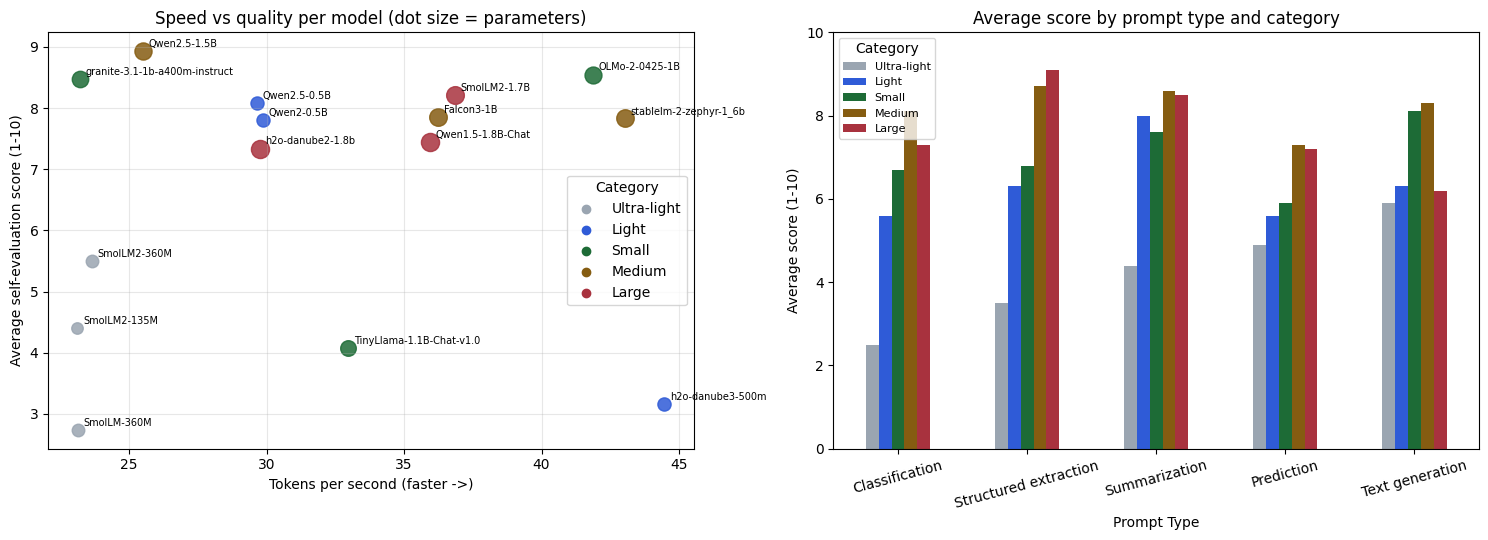

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colours = dict(zip(CATEGORY_ORDER, ["#9aa5b1", "#2f5bd7", "#1d6b36", "#855c11", "#a8323e"]))
for _, row in by_model.iterrows():
    axes[0].scatter(row["tokens_per_sec"], row["avg_score"], s=60 + 60 * row["Parameters (B)"],
                    color=colours[row["Model Category"]], alpha=0.85)
    axes[0].annotate(row["Model"].replace("-Instruct", "").replace("-chat", ""),
                     (row["tokens_per_sec"], row["avg_score"]), fontsize=7,
                     xytext=(4, 3), textcoords="offset points")
for category, colour in colours.items():
    axes[0].scatter([], [], color=colour, label=category)
axes[0].legend(title="Category")
axes[0].set_xlabel("Tokens per second (faster ->)")
axes[0].set_ylabel("Average self-evaluation score (1-10)")
axes[0].set_title("Speed vs quality per model (dot size = parameters)")
axes[0].grid(alpha=0.3)

type_by_category.T.plot.bar(ax=axes[1], color=[colours[c] for c in type_by_category.index])
axes[1].set_ylabel("Average score (1-10)")
axes[1].set_title("Average score by prompt type and category")
axes[1].set_ylim(0, 10)
axes[1].tick_params(axis="x", rotation=15)
axes[1].legend(title="Category", fontsize=8)
plt.tight_layout()
plt.savefig("results/speed_vs_quality.png", dpi=120)
plt.show()

### Handoff for Part 2 (Connor): per-model speed and size

`results/model_speed_summary.csv` holds what the cost model needs for every model: tokens per
second and latency on a single T4 GPU, the average prompt and answer lengths on DataPact's
prompts, and peak GPU memory.

In [13]:
speed_summary = by_model[["Model Category", "Model", "Parameters (B)", "tokens_per_sec", "latency_s",
                          "ttft_s", "avg_prompt_tokens", "avg_new_tokens", "peak_mem_gb", "avg_score"]]
speed_summary.to_csv("results/model_speed_summary.csv", index=False)
speed_summary

,Model Category,Model,Parameters (B),tokens_per_sec,latency_s,ttft_s,avg_prompt_tokens,avg_new_tokens,peak_mem_gb,avg_score
0,Ultra-light,SmolLM2-135M-Instruct,0.13,23.12,3.68,0.06,163.32,86.72,0.29,4.40
1,Ultra-light,SmolLM-360M-Instruct,0.36,23.14,5.95,0.05,142.32,134.28,0.75,2.74
2,Ultra-light,SmolLM2-360M-Instruct,0.36,23.64,3.05,0.05,163.32,72.08,0.75,5.50
3,Light,Qwen2-0.5B-Instruct,0.49,29.85,2.11,0.04,136.88,63.04,1.01,7.80
4,Light,Qwen2.5-0.5B-Instruct,0.49,29.64,2.30,0.04,146.88,67.80,1.01,8.08
5,Light,h2o-danube3-500m-chat,0.51,44.46,2.43,0.03,148.96,108.36,1.06,3.16
6,Small,TinyLlama-1.1B-Chat-v1.0,1.10,32.97,3.86,0.04,154.92,127.20,2.24,4.08
7,Small,granite-3.1-1b-a400m-instruct,1.33,23.21,2.45,0.10,186.56,58.08,2.72,8.48
8,Small,OLMo-2-0425-1B-Instruct,1.48,41.87,0.86,0.03,124.88,36.20,3.01,8.55
9,Medium,Qwen2.5-1.5B-Instruct,1.54,25.50,1.78,0.05,146.88,45.40,3.11,8.93


In [14]:
# Sample raw outputs: the best and worst scored answer for each prompt type.
for kind in PROMPT_TYPES:
    subset = bench[bench["Prompt Type"] == kind].sort_values("score")
    for label, row in (("LOWEST", subset.iloc[0]), ("HIGHEST", subset.iloc[-1])):
        print(f"=== {kind} | {label} | {row['Model']} on {row['Prompt ID']} | score {row['score']} ===")
        print(str(row["output"])[:500], "\n")

=== Classification | LOWEST | SmolLM-360M-Instruct on C2 | score 1.0 ===
Here's how you can implement this:

```python
import json

def validate_data_quality(data):
    data_dict = json.loads(data)
    if "data_type" not in data_dict or "data_value" not in data_dict:
        return False
    if "data_value" not in data_dict:
        return False
    if "data_type" not in data_dict:
        return False
    if "data_value" not in data_dict["data_value"]:
        return False
    if "data 

=== Classification | HIGHEST | Qwen1.5-1.8B-Chat on C5 | score 10.0 ===
{
  "likely_cause": "DATA_ISSUE",
  "reason": "The payroll deductions export column contains invalid values ('12..50' and 'N/A'). The rule specified that only numbers should be present in the column, but the sample values provided do not match this requirement."
} 

=== Structured extraction | LOWEST | SmolLM2-135M-Instruct on E1 | score 1.0 ===
The data-contract rule described in the message is:

"RANGE: Allowed_VALUES: [1, 2, 3,

## Step 1.6: Analysis

*Step 1.6: Tejas (took this part over from Ashok). Every number below comes from the 375 scored
answers above (15 models x 25 prompts, each model on every prompt) and the `by_model`,
`by_category` and prompt-type tables.*

### 1. Which model category produced the best outputs?

**Medium (1.5B-1.7B) had the best outputs, averaging 8.21 out of 10.** It was also the most
consistent category: every Medium model scored at least 7.84, and the gap between its best and worst model was 1.09 points.
In the Light and Small categories that gap was 4.9 and 4.5 points.

| Category | Params | Avg score | Best model | Worst model |
|---|---|---|---|---|
| Ultra-light | 0.13-0.36B | 4.21 | 5.50 | 2.74 |
| Light | 0.49-0.51B | 6.35 | 8.08 | 3.16 |
| Small | 1.10-1.48B | 7.04 | 8.55 | 4.08 |
| **Medium** | 1.54-1.67B | **8.21** | 8.93 | 7.84 |
| Large | 1.71-1.84B | 7.67 | 8.22 | 7.34 |

Medium had the best category average for classification (8.1), prediction (7.3), summarization
(8.6) and text generation (8.3). Large led only structured extraction (9.1).

A category average is not the same as a model result. The best single model is
Qwen2.5-1.5B-Instruct (Medium, 8.93). The next two are both in **Small**: OLMo-2-1B (8.55) and
Granite-3.1-1B-A400M (8.48). TinyLlama-1.1B (4.08) pulls Small's average down.

### 2. Did larger models always perform better?

**No.** The smallest models were clearly worst: nothing under 0.4B averaged above 5.5. Above
about 0.5B, though, size stopped predicting quality:

- **Large averaged lower than Medium** (7.67 vs 8.21). OLMo-2-1B (1.48B) and Granite (1.33B in
  total, about 400M active, since it is a mixture-of-experts model) both beat all three Large models.
- **A newer small model beat an older large one from the same family.** Qwen2.5-0.5B (8.08) beat
  Qwen1.5-1.8B (7.44), a model 3.8x its size. On the same 25 prompts it won 11, tied 9 and lost 5.
- **Models of the same size differed widely.** Qwen2.5-0.5B scored 8.08 and h2o-danube3-500m
  scored 3.16. TinyLlama-1.1B (4.08) scored below SmolLM2-135M (4.40), which is 8x smaller.
- Across the 15 models, the correlation between parameters and score is 0.64, but the rank
  correlation is only 0.43. Leaving out the Ultra-light group, the correlation drops to 0.42, so the
  trend mostly comes from the smallest models failing.

The weak models failed on instructions and format more than on content. SmolLM-360M ran into the
token limit on 24 of 25 prompts, TinyLlama on 18 and h2o-danube3-500m on 16. They wrote code,
repeated the input or ignored the JSON format. How a model was instruction-tuned mattered more than its size.

*Scope:* all 15 models are under 2B (Step 1.1), so "Large" here means 1.7-1.8B. These results say
nothing about 7B+ models.

### 3. Which model gave the best balance between speed and output quality?

**OLMo-2-0425-1B-Instruct (Small).** It scored 8.55 (2nd of 15) with the **lowest latency of any
model: 0.86 s per answer**. The next fastest took 1.60 s. Its speed was 41.9 tokens/s (3rd of 15).
It had no answer scoring 3 or below, it passed every format check on all 25 prompts, and it peaked
at 3.0 GB of GPU memory.

**Two different speed measures.** *Tokens/s* is new tokens divided by the end-to-end time for that
answer, averaged over the 25 prompts. *Latency* is the end-to-end seconds per answer, so it also
depends on how long the answer is. h2o-danube3-500m had the highest tokens/s (44.5) but still took
2.43 s per answer, because it wrote long answers (108 tokens on average) and scored only 3.16. For a
user waiting on an explanation, latency at an acceptable score is what counts, so we judge the
balance on score and latency together, not on either one alone.

Only two models are on the speed-quality frontier (no other model is both faster and better):

| Model | Avg score | Latency (s) | Tokens/s | Avg answer tokens |
|---|---|---|---|---|
| OLMo-2-0425-1B-Instruct | 8.55 | **0.86** | 41.87 | 36 |
| Qwen2.5-1.5B-Instruct | **8.93** | 1.78 | 25.50 | 45 |

On the same prompts, Qwen2.5-1.5B scored 0.38 higher (paired standard error 0.19; it won 9, tied
13 and lost 3). OLMo was faster on 23 of 25 prompts and took half the time on average. OLMo's low
latency comes partly from writing short answers, and short answers are what DataPact's
JSON and 1-2 sentence formats call for.

**Smaller did not mean faster.** Model averages ranged from 23 to 44 tokens/s regardless of size: the
135M model ran at 23 tokens/s, slower than every model above 1B. On a T4 serving one request at a time,
fixed per-token overhead outweighs the model's own computation. A smaller model saves memory, not time.

### What this means for DataPact

- The app currently uses SmolLM2-1.7B, chosen in A6. Here it scored 8.22 at 1.60 s. OLMo-2-1B
  scored 8.55 at 0.86 s. The score difference is not significant (+0.33, paired standard error
  0.33, 8 wins / 9 ties / 8 losses), but the latency difference is large. So OLMo-2-1B is a
  reasonable fast default, and Qwen2.5-1.5B is the choice when quality matters most. The routing
  design in Part 3 (`system_design.md`) uses these two as its local models.
- Prediction was the hardest type at the top end: no model averaged above 8.0 on it, while every
  other type had a model at 9.2 or higher. It was also the weakest type for the Small and Medium
  categories. Trend prediction is a candidate for a stronger model or plain code.
- A7 is independent of the Django app; nothing in the app was changed.

*Limits:* the scores come from an automated rubric (Step 1.4) on 25 prompts, 5 per type, so model
differences under about 0.4 points are within noise. Speeds come from one run on one Colab T4,
one request at a time. A model's first prompts include some warm-up: SmolLM2-135M's first four
answers ran at 9-16 tokens/s, against about 25 afterwards.


# Part 2: Cost Comparison and Infrastructure Planning

*Steps 2.1-2.4: Connor Slattery (from his `A7_Part1_Costs.ipynb`). Step 2.5: Tejas.*

In this section we estimate what it would cost to run DataPact's AI feature (explaining a failed
data check) at six traffic levels, from 1,000 to 100 million daily users. We compare two setups:

- Local hosting (Step 2.3): we rent GPU machines and run the models ourselves.
- Hugging Face API (Step 2.4): we pay a hosted model per token.

**What changed from Connor's notebook.** His version used the A6 speeds as placeholders until
Step 1.5 was finished. Here the models and speeds are read from Step 1.1 (`MODELS`) and Step 1.5
(`speed_summary`) above. Two variables are renamed so they don't overwrite Part 1's
names: the model list is `COST_MODELS` (Part 1 has `MODELS`) and the token-load table is
`token_load` (Part 1 has a `load()` function). The tables are saved in `results/`. The calculations
are unchanged.

**How these outputs were produced.** The Part 1 outputs above come from the Colab T4 run. The
Part 2 and Part 3 cells were run separately, on a local machine, from the Step 1.5 CSVs in
`results/`, so their execution counts are blank. With `SMOKE_TEST=1` (2 models), the notebook stops
at the next cell with a message, because Parts 2-3 need all 15 models.

These cells need no GPU. If this section is run on its own, it reads
`results/model_speed_summary.csv`.


## Setup and inputs from Part 1

In [ ]:
import math

pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)

if SMOKE_TEST:
    raise RuntimeError("SMOKE_TEST=1 benchmarks only 2 models; Parts 2-3 need all 15. Stopping here.")

if "speed_summary" not in globals():
    speed_summary = pd.read_csv("results/model_speed_summary.csv")

# (category, model, parameters in billions): the 15 models from Step 1.1
COST_MODELS = [(category, model_id.split("/")[-1], params) for category, model_id, params in MODELS]

# Tokens per second for each model, measured in Step 1.5 (one request at a time on a T4)
TOKENS_PER_SECOND = dict(zip(speed_summary["Model"], speed_summary["tokens_per_sec"]))
SPEED_SOURCE = "Step 1.5 benchmark (T4 GPU)"
assert set(TOKENS_PER_SECOND) == {m for _, m, _ in COST_MODELS}, "every model needs a speed"
print(len(COST_MODELS), "models | speeds from:", SPEED_SOURCE)


15 models | speeds from: Step 1.5 benchmark (T4 GPU)


### Why tokens per second

We use tokens per second instead of total answer time on purpose. Some of the small models ramble
(SmolLM-360M averaged 134 new tokens per answer in Step 1.5), so their total time says more about
the rambling than the speed. A real DataPact answer is about 54 tokens (see Step 2.1), so we
estimate the time per request as 54 / tokens per second.

As a sanity check, SmolLM2-1.7B took 1.5 seconds per answer on the app's real prompt in A6. With
its Step 1.5 speed, this formula gives 54 / 36.86 = 1.47 seconds.


## Step 2.1: Average tokens per request

A DataPact request asks the model to explain one failed check. The app sends a prompt with three
worked examples (the few-shot prompt we picked in A6) and gets a short JSON answer back.

We measured this in A6 with SmolLM2-1.7B, the model the app uses (`prompting_results.csv`):

- input (prompt): 602 tokens
- output (answer): 54 tokens
- total: 656 tokens per request

Our live Groq calls from A6 used 639 and 678 tokens, which lines up.

Like the formula in Step 2.2, we assume each daily active user makes one AI request per day.
`REQUESTS_PER_USER_PER_DAY` can be changed to test heavier use.

In [ ]:
INPUT_TOKENS = 602
OUTPUT_TOKENS = 54
AVG_TOKENS_PER_REQUEST = INPUT_TOKENS + OUTPUT_TOKENS
REQUESTS_PER_USER_PER_DAY = 1

# seconds for one request on one T4 GPU
SECONDS_PER_ANSWER = {m: OUTPUT_TOKENS / tps for m, tps in TOKENS_PER_SECOND.items()}

print("Average tokens per request:", AVG_TOKENS_PER_REQUEST)
print(f"Check: SmolLM2-1.7B estimated {SECONDS_PER_ANSWER['SmolLM2-1.7B-Instruct']:.2f} s per request "
      "(measured on the real app prompt in A6: 1.5 s)")

Average tokens per request: 656
Check: SmolLM2-1.7B estimated 1.47 s per request (measured on the real app prompt in A6: 1.5 s)


## Step 2.2: Total daily token load

In [ ]:
TRAFFIC = [
    ("Prototype", 1_000),
    ("Early Startup", 10_000),
    ("Growing Product", 100_000),
    ("Large Platform", 1_000_000),
    ("Mass Consumer App", 10_000_000),
    ("Global Platform", 100_000_000),
]

token_load = pd.DataFrame(TRAFFIC, columns=["Daily Traffic Category", "Daily Active Users"])
token_load["Requests per Day"] = token_load["Daily Active Users"] * REQUESTS_PER_USER_PER_DAY
token_load["Avg Tokens per Request"] = AVG_TOKENS_PER_REQUEST
token_load["Total Daily Token Load"] = token_load["Requests per Day"] * AVG_TOKENS_PER_REQUEST
token_load.style.format({c: "{:,}" for c in token_load.columns[1:]})

,Daily Traffic Category,Daily Active Users,Requests per Day,Avg Tokens per Request,Total Daily Token Load
0,Prototype,"1,000","1,000",656,"656,000"
1,Early Startup,"10,000","10,000",656,"6,560,000"
2,Growing Product,"100,000","100,000",656,"65,600,000"
3,Large Platform,"1,000,000","1,000,000",656,"656,000,000"
4,Mass Consumer App,"10,000,000","10,000,000",656,"6,560,000,000"
5,Global Platform,"100,000,000","100,000,000",656,"65,600,000,000"


## Step 2.3: Local hosting cost (15 models x 6 traffic levels = 90 rows)

For the cloud machine we picked an AWS g4dn.4xlarge: 16 vCPUs, 64 GiB of RAM and one NVIDIA T4
GPU. That matches the setup the assignment suggests, and it's the same GPU our A6 speeds came
from. It costs $1.204 an hour on demand, or $28.90 a day.

How we get the number of machines:

1. One request takes 54 / tokens per second seconds on one machine.
2. Over a full day, one machine can handle 86,400 / that many requests.
3. We only plan for 70% of that, so there's room for busy hours.
4. Machines needed = requests per day / requests per machine, rounded up, with a minimum of 1.

The speeds were measured one request at a time. Real serving software can batch several requests
together, which would cut the machine count a lot. The scaling section at the end looks at that.

In [ ]:
MACHINE_NAME = "AWS g4dn.4xlarge (16 vCPU, 64 GiB RAM, 1x T4 GPU)"
MACHINE_PRICE_PER_HOUR = 1.204
MACHINE_COST_PER_DAY = MACHINE_PRICE_PER_HOUR * 24
TARGET_UTILIZATION = 0.70
REQUESTS_AT_ONCE = 1   # speeds were measured one request at a time


def requests_per_machine_per_day(seconds_per_answer, at_once=REQUESTS_AT_ONCE):
    return 86_400 / seconds_per_answer * at_once * TARGET_UTILIZATION


local_rows = []
for category, model, params in COST_MODELS:
    capacity = requests_per_machine_per_day(SECONDS_PER_ANSWER[model])
    for traffic, users in TRAFFIC:
        requests = users * REQUESTS_PER_USER_PER_DAY
        machines = max(1, math.ceil(requests / capacity))
        local_rows.append({
            "Model Name": model,
            "Model Category": category,
            "Daily Traffic Category": traffic,
            "Avg Tokens per User": AVG_TOKENS_PER_REQUEST * REQUESTS_PER_USER_PER_DAY,
            "Total Daily Token Load": requests * AVG_TOKENS_PER_REQUEST,
            "Per Machine Cost (Cloud, $/day)": round(MACHINE_COST_PER_DAY, 2),
            "Machines Needed": machines,
            "Total Machine Cost ($/day)": round(machines * MACHINE_COST_PER_DAY, 2),
        })
local = pd.DataFrame(local_rows)
print(len(local), "rows | speeds from:", SPEED_SOURCE)
local.style.format({"Total Daily Token Load": "{:,}", "Machines Needed": "{:,}",
                    "Per Machine Cost (Cloud, $/day)": "${:,.2f}", "Total Machine Cost ($/day)": "${:,.2f}"})

90 rows | speeds from: Step 1.5 benchmark (T4 GPU)


,Model Name,Model Category,Daily Traffic Category,Avg Tokens per User,Total Daily Token Load,"Per Machine Cost (Cloud, $/day)",Machines Needed,Total Machine Cost ($/day)
0,SmolLM2-135M-Instruct,Ultra-light,Prototype,656,"656,000",$28.90,1,$28.90
1,SmolLM2-135M-Instruct,Ultra-light,Early Startup,656,"6,560,000",$28.90,1,$28.90
2,SmolLM2-135M-Instruct,Ultra-light,Growing Product,656,"65,600,000",$28.90,4,$115.58
3,SmolLM2-135M-Instruct,Ultra-light,Large Platform,656,"656,000,000",$28.90,39,"$1,126.94"
4,SmolLM2-135M-Instruct,Ultra-light,Mass Consumer App,656,"6,560,000,000",$28.90,387,"$11,182.75"
5,SmolLM2-135M-Instruct,Ultra-light,Global Platform,656,"65,600,000,000",$28.90,"3,862","$111,596.35"
6,SmolLM-360M-Instruct,Ultra-light,Prototype,656,"656,000",$28.90,1,$28.90
7,SmolLM-360M-Instruct,Ultra-light,Early Startup,656,"6,560,000",$28.90,1,$28.90
8,SmolLM-360M-Instruct,Ultra-light,Growing Product,656,"65,600,000",$28.90,4,$115.58
9,SmolLM-360M-Instruct,Ultra-light,Large Platform,656,"656,000,000",$28.90,39,"$1,126.94"


## Step 2.4: Hugging Face API cost (15 models x 6 traffic levels = 90 rows)

Hugging Face Inference Providers charges whatever the provider charges, with no markup. The
smallest paid chat model listed there is google/gemma-3-4b-it (through DeepInfra), at $0.05 per
million input tokens and $0.10 per million output tokens. None of our 15 models are sold as a
paid API since they're all under 2B parameters, so gemma-3-4b-it is the closest match for every
one of them. That's why the API price is the same in each row; the model choice only changes the
local cost.

Cost per request = 602 input tokens x $0.05/1M + 54 output tokens x $0.10/1M.

With an API we don't need GPUs, but we still need servers to run the DataPact web app that makes
the calls. We used AWS t3.large servers (2 vCPU, 8 GiB RAM, $0.0832 an hour). Our estimate is that
one server can pass along about 10 requests per second, since it's mostly waiting on the API,
planned at the same 70%.

In [ ]:
API_MODEL = "google/gemma-3-4b-it (DeepInfra via Hugging Face)"
API_PRICE_INPUT = 0.05 / 1_000_000    # $ per input token
API_PRICE_OUTPUT = 0.10 / 1_000_000   # $ per output token
API_COST_PER_REQUEST = INPUT_TOKENS * API_PRICE_INPUT + OUTPUT_TOKENS * API_PRICE_OUTPUT
API_COST_PER_TOKEN = API_COST_PER_REQUEST / AVG_TOKENS_PER_REQUEST   # blended, for the table

APP_SERVER_PRICE_PER_DAY = 0.0832 * 24
APP_SERVER_REQUESTS_PER_SECOND = 10
APP_SERVER_REQUESTS_PER_DAY = APP_SERVER_REQUESTS_PER_SECOND * 86_400 * TARGET_UTILIZATION

print(f"API cost per request: ${API_COST_PER_REQUEST:.7f}")
print(f"Blended API cost per token: ${API_COST_PER_TOKEN:.10f}  (${API_COST_PER_TOKEN * 1e6:.4f} per 1M tokens)")

api_rows = []
for category, model, params in COST_MODELS:
    for traffic, users in TRAFFIC:
        requests = users * REQUESTS_PER_USER_PER_DAY
        api_cost = requests * API_COST_PER_REQUEST
        servers = max(1, math.ceil(requests / APP_SERVER_REQUESTS_PER_DAY))
        api_rows.append({
            "Local LLM Model": model,
            "Local LLM Model Size": f"{params}B ({category})",
            "Comparable Paid Model Hosted on Hugging Face": API_MODEL,
            "Cost of Paid API per Token ($)": API_COST_PER_TOKEN,
            "Same, per 1M Tokens ($)": round(API_COST_PER_TOKEN * 1_000_000, 4),
            "Daily Traffic Category": traffic,
            "Total Token Load": requests * AVG_TOKENS_PER_REQUEST,
            "Estimated API Cost ($/day)": round(api_cost, 2),
            "Machines Required (API infrastructure)": servers,
            "Total Cost ($/day)": round(api_cost + servers * APP_SERVER_PRICE_PER_DAY, 2),
        })
api = pd.DataFrame(api_rows)
print(len(api), "rows")
api.style.format({"Cost of Paid API per Token ($)": "{:.10f}", "Same, per 1M Tokens ($)": "${:.4f}",
                  "Total Token Load": "{:,}",
                  "Machines Required (API infrastructure)": "{:,}",
                  "Estimated API Cost ($/day)": "${:,.2f}", "Total Cost ($/day)": "${:,.2f}"})

API cost per request: $0.0000355
Blended API cost per token: $0.0000000541  ($0.0541 per 1M tokens)
90 rows


,Local LLM Model,Local LLM Model Size,Comparable Paid Model Hosted on Hugging Face,Cost of Paid API per Token ($),"Same, per 1M Tokens ($)",Daily Traffic Category,Total Token Load,Estimated API Cost ($/day),Machines Required (API infrastructure),Total Cost ($/day)
0,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Prototype,"656,000",$0.04,1,$2.03
1,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Early Startup,"6,560,000",$0.36,1,$2.35
2,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Growing Product,"65,600,000",$3.55,1,$5.55
3,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Large Platform,"656,000,000",$35.50,2,$39.49
4,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Mass Consumer App,"6,560,000,000",$355.00,17,$388.95
5,SmolLM2-135M-Instruct,0.13B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Global Platform,"65,600,000,000","$3,550.00",166,"$3,881.47"
6,SmolLM-360M-Instruct,0.36B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Prototype,"656,000",$0.04,1,$2.03
7,SmolLM-360M-Instruct,0.36B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Early Startup,"6,560,000",$0.36,1,$2.35
8,SmolLM-360M-Instruct,0.36B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Growing Product,"65,600,000",$3.55,1,$5.55
9,SmolLM-360M-Instruct,0.36B (Ultra-light),google/gemma-3-4b-it (DeepInfra via Hugging Face),0.0000000541,$0.0541,Large Platform,"656,000,000",$35.50,2,$39.49


### Local vs API

Daily cost at each traffic level: the cheapest local model, the most expensive one, and the API.

In [ ]:
per_traffic = local.groupby("Daily Traffic Category", sort=False)["Total Machine Cost ($/day)"]
compare = pd.DataFrame({
    "Daily Active Users": [u for _, u in TRAFFIC],
    "Local, cheapest model ($/day)": per_traffic.min().values,
    "Local, most expensive model ($/day)": per_traffic.max().values,
    "API total ($/day)": api.groupby("Daily Traffic Category", sort=False)["Total Cost ($/day)"].first().values,
}, index=[t for t, _ in TRAFFIC])
compare["Cheaper option"] = ["API" if a < l else "Local" for a, l in
                             zip(compare["API total ($/day)"], compare["Local, cheapest model ($/day)"])]
compare.style.format({"Daily Active Users": "{:,}", **{c: "${:,.2f}" for c in compare.columns[1:4]}})

,Daily Active Users,"Local, cheapest model ($/day)","Local, most expensive model ($/day)",API total ($/day),Cheaper option
Prototype,"1,000",$28.90,$28.90,$2.03,API
Early Startup,"10,000",$28.90,$28.90,$2.35,API
Growing Product,"100,000",$86.69,$115.58,$5.55,API
Large Platform,"1,000,000",$606.82,"$1,126.94",$39.49,API
Mass Consumer App,"10,000,000","$5,808.10","$11,182.75",$388.95,API
Global Platform,"100,000,000","$58,052.06","$111,596.35","$3,881.47",API


## Scaling: what if a GPU handles several requests at once?

Everything above assumes one request at a time per GPU, because that's how the speeds were
measured. Serving tools can batch requests, so here we try 1, 8 and 32 requests at once for
SmolLM2-1.7B, the model the app uses. This assumes each request still takes the same time, so
treat it as a what-if, not a measurement.

In [ ]:
APP_MODEL = "SmolLM2-1.7B-Instruct"
rows = []
for at_once in (1, 8, 32):
    capacity = requests_per_machine_per_day(SECONDS_PER_ANSWER[APP_MODEL], at_once)
    for traffic, users in TRAFFIC:
        machines = max(1, math.ceil(users * REQUESTS_PER_USER_PER_DAY / capacity))
        rows.append({"Requests at once": at_once, "Daily Traffic Category": traffic,
                     "Machines Needed": machines, "Local cost ($/day)": machines * MACHINE_COST_PER_DAY})
batching = pd.DataFrame(rows).pivot(index="Daily Traffic Category", columns="Requests at once",
                                    values="Local cost ($/day)").reindex([t for t, _ in TRAFFIC])
batching["API total ($/day)"] = compare["API total ($/day)"]
batching.columns = [f"Local, {c} at once" if isinstance(c, int) else c for c in batching.columns]
batching.style.format("${:,.2f}")

,"Local, 1 at once","Local, 8 at once","Local, 32 at once",API total ($/day)
Daily Traffic Category,,,,
Prototype,$28.90,$28.90,$28.90,$2.03
Early Startup,$28.90,$28.90,$28.90,$2.35
Growing Product,$86.69,$28.90,$28.90,$5.55
Large Platform,$722.40,$115.58,$28.90,$39.49
Mass Consumer App,"$7,021.73",$895.78,$231.17,$388.95
Global Platform,"$70,015.01","$8,755.49","$2,196.10","$3,881.47"


## Save the tables

In [ ]:
token_load.to_csv("results/cost_token_load.csv", index=False)
local.to_csv("results/cost_local_hosting_90.csv", index=False)
api.to_csv("results/cost_hf_api_90.csv", index=False)
compare.to_csv("results/cost_local_vs_api.csv", index_label="Daily Traffic Category")
batching.round(2).to_csv("results/cost_batching_whatif.csv")
print("Saved 5 CSV files in results/")

Saved 5 CSV files in results/


## Sources and assumptions

Prices (all checked on Oct 23, 2026, AWS us-east-1 on-demand):

- AWS g4dn.4xlarge: $1.204/hour
- AWS t3.large: $0.0832/hour
- google/gemma-3-4b-it via DeepInfra on Hugging Face: $0.05 per 1M input tokens, $0.10 per 1M
  output tokens (Hugging Face passes provider prices through with no markup). Rechecked on Oct 26,
  2026 on DeepInfra's model page (deepinfra.com/google/gemma-3-4b-it): still $0.05 / $0.10.
  Some third-party price trackers show $0.04 / $0.08 (not confirmed).

Measured in A6: tokens per request (SmolLM2-1.7B, few-shot prompt). Measured in Step 1.5: tokens
per second on a T4, one request at a time.

Our assumptions, all adjustable in the cells above: one request per user per day, machines
planned at 70% busy, one app server handles about 10 requests per second, no reserved-instance
discounts, and one request at a time per GPU except in the scaling section.

Step 2.5 (below) uses the local, API and scaling tables above.

## Step 2.5: Analysis

*Step 2.5: Tejas.* **Every cost here is an estimate**, built from the assumptions listed above:
on-demand AWS prices, one 656-token request per user per day, machines planned at 70% busy, and
Step 1.5 speeds measured one request at a time. None of these are measured bills.

**Checks on the tables.** The local and API tables each have 90 rows (15 models x 6 traffic levels).
Token load is daily users x 656, from 656,000 to 65.6 billion tokens a day. Recomputing the machine
counts and costs from the formulas, separately from the code above, gave the same values in all 180
rows. The API table does not depend on model speed, so it matches Connor's A6-speed version
exactly. The local costs moved a little with the Step 1.5 speeds, but no conclusion changed.

**Key unit costs.** One T4 machine costs $28.90 a day. Serving one request at a time, even the
fastest model (h2o-danube3-500m, 44.5 tokens/s) handles only about 50,000 requests a day at 70%.
That works out to about $0.00058 per request. The API costs $0.0000355 per request, or $0.0000388
including the app servers, so local hosting costs about **15x more per request**.

### 1. At what scale is local hosting cheaper?

**At none of the six levels while a GPU serves one request at a time**, which is how Step 1.5
measured speed:

| Daily users | Cheapest local model ($/day) | API total ($/day) | Local / API |
|---|---|---|---|
| 1,000 | 28.90 | 2.03 | 14x |
| 10,000 | 28.90 | 2.35 | 12x |
| 100,000 | 86.69 | 5.55 | 16x |
| 1,000,000 | 606.82 | 39.49 | 15x |
| 10,000,000 | 5,808.10 | 388.95 | 15x |
| 100,000,000 | 58,052.06 | 3,881.47 | 15x |

Local hosting only wins with **batching** (one GPU serving many requests at once) **and** enough
traffic to keep that GPU busy:

- **Batching:** to match the API price, a T4 has to serve about 15-26 requests at once, depending
  on the model: about 15 for h2o-danube3, 16 for OLMo-2-1B, 18 for SmolLM2-1.7B and 26 for
  Qwen2.5-1.5B.
- **Volume:** one machine costs $28.90 a day. Counting web app servers on the API side only, as
  the tables do, the API reaches that cost at about 0.70 million requests a day. Counting them on
  both sides, it reaches it at about 0.81 million. Below roughly 0.7-0.8 million requests a day, one
  GPU cannot beat the API however well it batches.

In the what-if table, SmolLM2-1.7B at **32 requests at once** is cheaper than the API **from 1
million daily users up**: $28.90 vs $39.49 a day at 1M, $231 vs $389 at 10M, and $2,196 vs $3,881
at 100M. At 8 at once it never wins. The two sides of the 1M comparison are not quite alike: the
local figure has no web app servers, while the API figure includes two ($3.99). Adding the same two
servers to local gives $32.89, still below $39.49. *(The Part 1 handoff note said local wins "from 10M users
up"; the table shows 1M as well, though by only $10.59 a day.)*

### 2. At what scale is API usage cheaper?

**At every scale one request at a time, and below about 1 million daily users even with
batching.** The gap is widest for a small product. At 1,000 users the API costs $2.03 a day,
against $28.90 for a GPU that sits mostly idle: 1,000 SmolLM2-1.7B answers take about 24 minutes
of GPU time a day.

### 3. When would we switch our architecture?

- **Start on the API** (Prototype through Growing Product, up to about 100K daily users). It costs
  $2-6 a day, with no GPUs to run.
- **Move to self-hosting** once all of these hold:
  1. traffic stays at **1 million or more requests a day**;
  2. a load test shows our serving setup really sustains about **20 or more requests at once per
     T4** at acceptable latency. The what-if assumes batching doesn't slow each request, and we
     have not measured that;
  3. the savings outweigh the extra operations work. At 10M users the what-if saves about
     $158 a day (about $58K a year).
- **Keep the API as overflow** for peaks even after switching (Part 3), so GPUs can be sized for
  normal load rather than the busiest hour.
- **A non-cost reason can force the switch earlier.** DataPact's explanations include sample
  values from customers' data files. A customer who cannot send data to a third party needs local
  hosting at any scale.

**Assumptions that could change these answers:**

- **API quality was not measured.** The API stand-in, gemma-3-4b-it, is 4B, larger than any of
  our local models, and we never ran it on our 25 prompts.
- **API price.** Connor's $0.05 / $0.10 per 1M input / output tokens matches DeepInfra's own page for
  gemma-3-4b-it, rechecked on Oct 26, 2026. (Hugging Face lists DeepInfra as this model's provider.)
  Some third-party price trackers show $0.04 / $0.08. We did not confirm that, but it would favor
  the API even more. Prices can change.
- **Peak hours are not modeled.** Planning at 70% busy covers daily averages, not peak hours.
  Local hosting needs spare capacity for peaks; the API scales on its own. This favors the API.
- **Some costs are left out.** Local costs exclude operations work, monitoring and the web app
  servers, which the API side includes ($2 a day each). Reserved or spot pricing would lower local
  costs. We modeled neither.
- **Heavier use moves the crossover.** We assume one request per user per day. With more, both
  costs scale with requests, so the crossover arrives at fewer users.


# Part 3: Routing check on the benchmark data

*Part 3 (routing) is assigned to Ashok. This check and the routing section of `system_design.md`
(Steps 3.1-3.3) were drafted by Tejas during assembly and have not yet been reviewed by Ashok. The
cell tests one idea from that design on the measured Step 1.5 data.*

**Idea:** use a cheap model by default and re-ask a stronger one only when the answer fails a
check that needs no answer key: the right JSON keys and allowed values, the sentence and word
limits, no looping and no cut-off. In the rubric these checks are adherence = 3, structure = 1 and
clarity = 2. A real router could run them on every answer before returning it. *Latency* for an
escalated prompt is the first model's time plus the second model's time. The last row instead
routes *before* answering, by task type.


In [ ]:
# Checks that need no answer key, so a router could run them at serving time (on a copy of bench)
checked = bench.assign(passes_checks=(bench["adherence"] == 3) & (bench["structure"] == 1)
                       & (bench["clarity"] == 2))
wide = {col: checked.pivot(index="Prompt ID", columns="Model", values=col)
        for col in ["score", "Latency (s)", "passes_checks"]}


def one_model(model):
    return wide["score"][model].mean(), wide["Latency (s)"][model].mean(), 0.0


def escalate_on_failure(first, second):
    failed = ~wide["passes_checks"][first].astype(bool)
    score = wide["score"][first].where(~failed, wide["score"][second])
    latency = wide["Latency (s)"][first] + wide["Latency (s)"][second].where(failed, 0)
    return score.mean(), latency.mean(), failed.mean()


def route_by_type(types_to_second, first, second):
    prompt_type = checked.drop_duplicates("Prompt ID").set_index("Prompt ID")["Prompt Type"]
    use_second = prompt_type.reindex(wide["score"].index).isin(types_to_second)
    score = wide["score"][first].where(~use_second, wide["score"][second])
    latency = wide["Latency (s)"][first].where(~use_second, wide["Latency (s)"][second])
    return score.mean(), latency.mean(), use_second.mean()


OLMO, QWEN15, SMOL17 = "OLMo-2-0425-1B-Instruct", "Qwen2.5-1.5B-Instruct", "SmolLM2-1.7B-Instruct"
routing = pd.DataFrame({
    f"only {OLMO}": one_model(OLMO),
    f"only {QWEN15}": one_model(QWEN15),
    f"only {SMOL17} (current app model)": one_model(SMOL17),
    f"{OLMO} -> {QWEN15} if checks fail": escalate_on_failure(OLMO, QWEN15),
    f"{SMOL17} -> {QWEN15} if checks fail": escalate_on_failure(SMOL17, QWEN15),
    f"{QWEN15} -> {OLMO} if checks fail": escalate_on_failure(QWEN15, OLMO),
    f"by type: summaries + predictions -> {QWEN15}, rest -> {OLMO}":
        route_by_type({"Summarization", "Prediction"}, OLMO, QWEN15),
}, index=["Avg score", "Avg latency (s)", "Share escalated / routed"]).T.round(2)
display(routing)
print("Average score of answers that pass / fail the checks (all 15 models):",
      checked.groupby("passes_checks")["score"].mean().round(2).to_dict())
print("Share of answers passing the checks:",
      checked.groupby("Model")["passes_checks"].mean().round(2).sort_values(ascending=False).to_dict())


,Avg score,Avg latency (s),Share escalated / routed
only OLMo-2-0425-1B-Instruct,8.55,0.86,0.00
only Qwen2.5-1.5B-Instruct,8.93,1.78,0.00
only SmolLM2-1.7B-Instruct (current app model),8.22,1.60,0.00
OLMo-2-0425-1B-Instruct -> Qwen2.5-1.5B-Instruct if checks fail,8.55,0.86,0.00
SmolLM2-1.7B-Instruct -> Qwen2.5-1.5B-Instruct if checks fail,9.04,2.47,0.32
Qwen2.5-1.5B-Instruct -> OLMo-2-0425-1B-Instruct if checks fail,8.99,1.81,0.04
"by type: summaries + predictions -> Qwen2.5-1.5B-Instruct, rest -> OLMo-2-0425-1B-Instruct",8.77,1.14,0.40


Average score of answers that pass / fail the checks (all 15 models): {False: 4.88, True: 8.47}
Share of answers passing the checks: {'OLMo-2-0425-1B-Instruct': 1.0, 'Qwen2.5-1.5B-Instruct': 0.96, 'Qwen2.5-0.5B-Instruct': 0.72, 'Qwen2-0.5B-Instruct': 0.68, 'SmolLM2-1.7B-Instruct': 0.68, 'granite-3.1-1b-a400m-instruct': 0.64, 'stablelm-2-zephyr-1_6b': 0.64, 'Falcon3-1B-Instruct': 0.6, 'Qwen1.5-1.8B-Chat': 0.6, 'h2o-danube2-1.8b-chat': 0.52, 'SmolLM2-360M-Instruct': 0.28, 'SmolLM2-135M-Instruct': 0.16, 'h2o-danube3-500m-chat': 0.12, 'SmolLM-360M-Instruct': 0.0, 'TinyLlama-1.1B-Chat-v1.0': 0.0}


**What the check shows** (25 prompts, in-sample, so treat these as indicative):

- **The checks are a useful confidence signal.** Answers that pass them average 8.47, and answers
  that fail average 4.88.
- **Escalation helps a model that breaks format.** SmolLM2-1.7B (the current app model) failed the
  checks on 32% of prompts. Sending those prompts to Qwen2.5-1.5B raised the average from 8.22 to
  **9.04**, better than either model alone, at 2.47 s on average.
- **It does nothing for OLMo-2-1B**, because OLMo passed the checks on every prompt. Its mistakes
  are wrong content, such as a wrong label or a missing fact, which format checks cannot see. To
  catch those, the router has to choose by task type or prompt length *before* answering. That
  is the design in `system_design.md`.
- **Routing by task type** sends summaries and predictions, the two types where Qwen2.5-1.5B beat
  OLMo by the most (+0.7 and +0.4), to Qwen2.5-1.5B and everything else to OLMo. It scored **8.77
  at 1.14 s**, against 8.55 at 0.86 s for OLMo alone and 8.93 at 1.78 s for Qwen alone. That
  captures about 58% of Qwen's quality gain for about 30% of its extra latency. The rule was
  picked by looking at these same 25 prompts, so the estimate is optimistic until it is tested on
  new prompts.


## Download the results (Colab only)

Zips `results/` and downloads it. Then save this notebook with *File > Download > Download .ipynb*
so its outputs are kept.

In [15]:
if IN_COLAB:
    from google.colab import files
    shutil.make_archive("results", "zip", "results")
    files.download("results.zip")
else:
    print("Not in Colab - results are already in ./results")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>